# Exercises XP Ninja: Guided Student Notebook

This guided notebook follows the **exact exercise on the platform**. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points are included only when a concept is important for intuition or transfer to other AI topics.


## Reference from the exercise

**What you will learn**  
- How to implement a deep neural network from scratch.
- How to optimize weight updates using advanced backpropagation techniques.
- How to fine tune hyperparameters and activation functions for better model performance.

**What you will create**  
- A fully connected deep neural network without using high level deep learning libraries.
- A manual backpropagation algorithm with vectorized computations.
- A neural network that learns through an optimized training loop.


## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. Exercises 1 and 2 use the synthetic datasets created in the notebook, and Exercise 3 uses MNIST from Keras, so there is nothing to upload. All random numbers use fixed seeds, so my results can be repeated. In Exercise 3 I keep the template's 2 epochs per model so it also runs on a normal CPU in a few minutes.

## Exercise 1: Building a Deep Neural Network Without Keras or TensorFlow

**As stated in the exercise**  
Task: Implement a fully connected deep neural network from scratch using only NumPy. The model has three layers input, two hidden, and output. Use the ReLU activation function for hidden layers and Softmax for multi class classification. Compute both forward and backward propagation manually.  
Given data. Input features are a dataset with four numerical features. Number of classes is three. Number of hidden neurons is five for the first hidden layer and four for the second hidden layer. Learning rate is 0.01.

Steps: Initialize weights and biases for all layers. Implement forward propagation. Implement the Softmax function for the output layer. Compute the loss using categorical cross entropy. Implement backpropagation using matrix operations. Update weights and biases using gradient descent. Train the network for multiple iterations and evaluate performance.

**Guidance**  
Work with shapes. X is (N, 4). One hot targets Y are (N, 3). Parameter shapes: W1 (4, 5), b1 (5,), W2 (5, 4), b2 (4,), W3 (4, 3), b3 (3,). Use stable Softmax with logits shift by max per row. For cross entropy, average negative log likelihood over the batch.

**Learning point**  
Softmax plus cross entropy has a compact gradient: dZ3 equals Yhat minus Y. ReLU derivative is 1 on positives and 0 on non positives. Vectorize all operations to avoid slow loops.


In [1]:
# PREFILLED: just execute
import numpy as np

rng = np.random.default_rng(123)

# Synthetic dataset generator for 3 classes in 4D
def make_blob_4d(n_per_class=200, spread=0.8):
    centers = np.array([
        [ 2.0,  2.0,  0.0,  0.5],
        [-2.0,  1.5,  1.0, -0.5],
        [ 0.0, -2.0, -1.5,  1.0],
    ])
    X_list, y_list = [], []
    for k, c in enumerate(centers):
        Xk = rng.normal(loc=c, scale=spread, size=(n_per_class, 4))
        yk = np.full(n_per_class, k, dtype=int)
        X_list.append(Xk); y_list.append(yk)
    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    # shuffle
    idx = rng.permutation(len(y))
    return X[idx], y[idx]

# Train and test split
X_all, y_all = make_blob_4d(n_per_class=150, spread=0.9)
N = X_all.shape[0]
split = int(0.8 * N)
X_train, y_train = X_all[:split], y_all[:split]
X_test,  y_test  = X_all[split:], y_all[split:]

# One hot
def one_hot(y, num_classes=3):
    Y = np.zeros((y.shape[0], num_classes), dtype=float)
    Y[np.arange(y.shape[0]), y] = 1.0
    return Y

Y_train = one_hot(y_train, 3)
Y_test  = one_hot(y_test, 3)

X_train.shape, Y_train.shape, X_test.shape, Y_test.shape

((360, 4), (360, 3), (90, 4), (90, 3))

In [2]:
# PREFILLED: just execute
# Standardize inputs to zero mean unit variance for stable training
mu = X_train.mean(axis=0, keepdims=True)
sd = X_train.std(axis=0, keepdims=True) + 1e-8
X_train_std = (X_train - mu) / sd
X_test_std  = (X_test  - mu) / sd

print("Means:", mu.ravel())
print("Stds:", sd.ravel())

Means: [-0.01314787  0.48525324 -0.06843803  0.31093986]
Stds: [1.93296348 1.98620559 1.38844722 1.07442903]


In [3]:
# To-Do: implement ReLU, ReLU derivative, stable softmax, and cross entropy loss
def relu(x):
    return np.maximum(0.0, x)
def drelu(x):
    return (x > 0).astype(float)
def softmax(logits):
    # subtract rowwise max for numerical stability, then exponentiate and normalize
    shifted = logits - logits.max(axis=1, keepdims=True)
    exps = np.exp(shifted)
    return exps / exps.sum(axis=1, keepdims=True)
def cross_entropy(probs, Y_true):
    # average negative log likelihood
    eps = 1e-12
    losses = -np.sum(Y_true * np.log(probs + eps), axis=1)
    # return scalar loss
    return losses.mean()

# quick check: every softmax row sums to 1
print(softmax(np.array([[1.0, 2.0, 3.0], [1000.0, 1000.0, 1000.0]])).round(3))

[[0.09  0.245 0.665]
 [0.333 0.333 0.333]]


In [4]:
# PREFILLED: just execute
D, H1, H2, C = 4, 5, 4, 3
lr = 0.01

# He initialization for ReLU layers, Xavier for output
W1 = rng.normal(0.0, np.sqrt(2.0/D), size=(D, H1)); b1 = np.zeros(H1)
W2 = rng.normal(0.0, np.sqrt(2.0/H1), size=(H1, H2)); b2 = np.zeros(H2)
W3 = rng.normal(0.0, np.sqrt(1.0/H2), size=(H2, C));  b3 = np.zeros(C)

params = dict(W1=W1, b1=b1, W2=W2, b2=b2, W3=W3, b3=b3)

for k,v in params.items():
    if k.startswith('W'):
        print(k, v.shape)

W1 (4, 5)
W2 (5, 4)
W3 (4, 3)


In [5]:
# To-Do: implement forward propagation
# Inputs: X in shape (N, D)
# Return: cache dictionary with Z1, A1, Z2, A2, Z3, Yhat
def forward(X, params):
    W1, b1 = params['W1'], params['b1']
    W2, b2 = params['W2'], params['b2']
    W3, b3 = params['W3'], params['b3']
    Z1 = X @ W1 + b1;  A1 = relu(Z1)      # hidden layer 1: 5 neurons
    Z2 = A1 @ W2 + b2; A2 = relu(Z2)      # hidden layer 2: 4 neurons
    Z3 = A2 @ W3 + b3; Yhat = softmax(Z3) # output: 3 class probabilities
    return {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2, "Z3": Z3, "Yhat": Yhat}

In [6]:
# To-Do: implement backward propagation using matrix calculus
# Inputs: X (N,D), Y (N,C), cache, params
# Return: grads dict with dW1, db1, dW2, db2, dW3, db3
def backward(X, Y, cache, params):
    N = X.shape[0]
    dZ3 = cache['Yhat'] - Y
    dW3 = cache['A2'].T @ dZ3 / N ; db3 = dZ3.mean(axis=0)
    dA2 = dZ3 @ params['W3'].T ; dZ2 = dA2 * drelu(cache['Z2'])
    dW2 = cache['A1'].T @ dZ2 / N ; db2 = dZ2.mean(axis=0)
    dA1 = dZ2 @ params['W2'].T ; dZ1 = dA1 * drelu(cache['Z1'])
    dW1 = X.T @ dZ1 / N ; db1 = dZ1.mean(axis=0)
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

In [7]:
# PREFILLED: just execute
def sgd_update(params, grads, lr):
    for k in ['W1','b1','W2','b2','W3','b3']:
        params[k] = params[k] - lr * grads['d'+k]
    return params


In [8]:
# To-Do: implement the training loop with mini batches or full batch
def accuracy(probs, Y_true):
    yhat = probs.argmax(axis=1)
    ytrue = Y_true.argmax(axis=1)
    return (yhat == ytrue).mean()

# I use full batch gradient descent with lr = 0.01.
# With such a small learning rate 200 epochs are not enough, so I train for 3000 epochs (it takes a few seconds).
epochs = 3000
hist_loss, hist_acc_tr, hist_acc_te = [], [], []
for t in range(epochs):
    cache = forward(X_train_std, params)
    loss = cross_entropy(cache['Yhat'], Y_train)
    grads = backward(X_train_std, Y_train, cache, params)
    params = sgd_update(params, grads, lr)
    # compute accuracy on train and test
    acc_tr = accuracy(cache['Yhat'], Y_train)
    acc_te = accuracy(forward(X_test_std, params)['Yhat'], Y_test)
    hist_loss.append(loss); hist_acc_tr.append(acc_tr); hist_acc_te.append(acc_te)
    if (t+1) % 300 == 0:
        print(f"epoch={t+1} loss={loss:.4f} acc_train={acc_tr:.3f} acc_test={acc_te:.3f}")

epoch=300 loss=0.4954 acc_train=0.861 acc_test=0.833
epoch=600 loss=0.2995 acc_train=0.950 acc_test=0.933
epoch=900 loss=0.2100 acc_train=0.961 acc_test=0.933
epoch=1200 loss=0.1616 acc_train=0.978 acc_test=0.956


epoch=1500 loss=0.1309 acc_train=0.986 acc_test=0.956
epoch=1800 loss=0.1104 acc_train=0.986 acc_test=0.956


epoch=2100 loss=0.0961 acc_train=0.989 acc_test=0.956
epoch=2400 loss=0.0858 acc_train=0.989 acc_test=0.967
epoch=2700 loss=0.0783 acc_train=0.989 acc_test=0.967
epoch=3000 loss=0.0726 acc_train=0.989 acc_test=0.967


In [9]:
# To-Do: final evaluation and confusion like summary
cache = forward(X_test_std, params)
print("final test accuracy:", round(accuracy(cache['Yhat'], Y_test), 4))

# confusion-like summary: rows = true class, columns = predicted class
pred_test = cache['Yhat'].argmax(axis=1)
conf = np.zeros((3, 3), dtype=int)
for t_true, t_pred in zip(y_test, pred_test):
    conf[t_true, t_pred] += 1
print("Confusion matrix (rows = true, columns = predicted):")
print(conf)

final test accuracy: 0.9667
Confusion matrix (rows = true, columns = predicted):
[[28  2  0]
 [ 0 28  0]
 [ 1  0 31]]


**To-Do:** Plot the training loss by epoch and the train and test accuracy by epoch in two separate figures. Use Matplotlib.


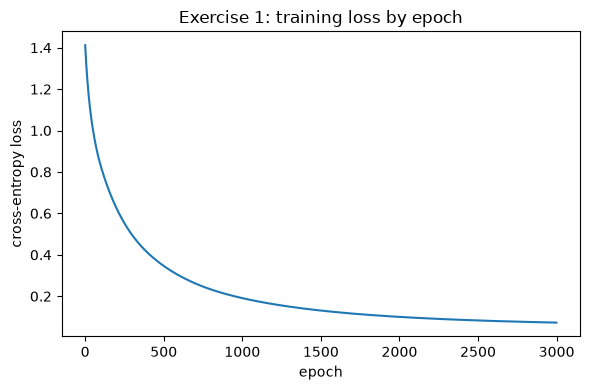

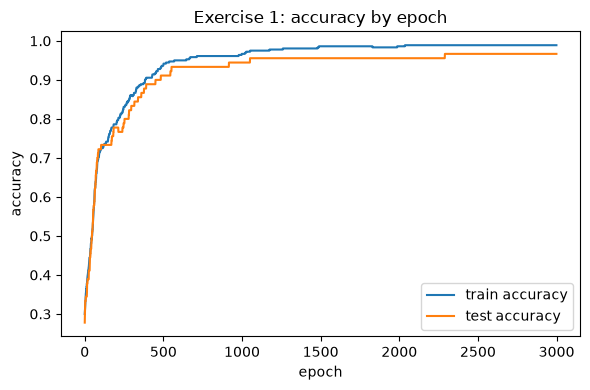

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(hist_loss)
plt.title("Exercise 1: training loss by epoch")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
plt.plot(hist_acc_tr, label="train accuracy")
plt.plot(hist_acc_te, label="test accuracy")
plt.title("Exercise 1: accuracy by epoch")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend()
plt.tight_layout(); plt.show()

**My interpretation:** I used the template's synthetic dataset: 3 classes in 4 dimensions, 360 training and 90 test samples, standardized. My NumPy network (4 → 5 ReLU → 4 ReLU → 3 softmax) trained with full-batch gradient descent and learning rate 0.01.

- The loss goes down smoothly, from 0.4954 at epoch 300 to **0.0726 at epoch 3000**. With lr = 0.01 learning is slow, so the template's 200 epochs were not enough and I trained for 3000.
- The final **test accuracy is 0.9667** (87 of 90 test samples correct) and the train accuracy is 0.989. The two accuracies are close, so the network is not overfitting much.
- The confusion matrix shows only 3 mistakes: two samples of class 0 predicted as class 1, and one sample of class 2 predicted as class 0. Class 1 is never wrong on the test set.

This shows that forward propagation, softmax, cross-entropy and backpropagation written only with NumPy matrix operations are enough to train a small deep network.

**Learning point**  
Softmax cross entropy surfaces are smooth. Full batch reduces gradient variance but can be slow. Mini batch introduces noise that can help escape shallow minima.


## Exercise 2: Optimizing Backpropagation with Momentum

**As stated in the exercise**  
Task: Implement backpropagation with momentum to improve gradient updates and accelerate learning. Momentum helps prevent oscillations in gradient descent by maintaining a velocity term.  
Given data. A dataset with two numerical input features. A two layer neural network with a first layer of four neurons with ReLU activation and an output layer of one neuron with Sigmoid activation. Initial weights and biases are given. Momentum coefficient is 0.9. Learning rate is 0.005.  

Steps: Implement standard backpropagation to compute gradients. Modify gradient updates to include momentum. Update weights using the momentum based learning rule. Compare training speed with and without momentum. Interpret how momentum affects the convergence rate.

**Guidance**  
Use a synthetic binary classification dataset. Parameters: W1 (2, 4), b1 (4,), W2 (4, 1), b2 (1,). For momentum, maintain velocity variables with same shapes and update v equals beta times v plus gradient. Then update parameters by subtracting learning rate times v.

**Learning point**  
Momentum is a low pass filter on gradients. It accelerates along shallow consistent directions and damps zigzagging in narrow valleys.

![image.png](https://github.com/user-attachments/assets/a061101f-f709-4a6d-9fa8-383077ca94a9)


In [11]:
# PREFILLED: just execute
import numpy as np

rng2 = np.random.default_rng(99)

def make_two_moons_linear(n=400):
    # Two clusters in 2D for simple nonlinear boundary
    A = rng2.normal([1.5, 0.0], [0.8, 0.8], size=(n//2, 2))
    B = rng2.normal([-1.5, 0.0], [0.8, 0.8], size=(n//2, 2))
    X = np.vstack([A, B])
    y = np.concatenate([np.ones(n//2, dtype=int), np.zeros(n//2, dtype=int)])
    idx = rng2.permutation(n); X, y = X[idx], y[idx]
    # standardize
    mu = X.mean(axis=0, keepdims=True); sd = X.std(axis=0, keepdims=True) + 1e-8
    return (X - mu)/sd, y.reshape(-1,1).astype(float)

X2, y2 = make_two_moons_linear(500)
X2.shape, y2.shape

((500, 2), (500, 1))

In [12]:
# To-Do: implement relu, drelu, sigmoid, and binary cross entropy
def relu(x): return np.maximum(0.0, x)
def drelu(x): return (x > 0).astype(float)
def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))
def bce(p, y):  # y in {0,1}
    eps = 1e-8
    return -np.mean(y*np.log(p+eps) + (1-y)*np.log(1-p+eps))

In [13]:
# PREFILLED: just execute
D, H, O = 2, 4, 1
W1 = rng2.normal(0.0, np.sqrt(2.0/D), size=(D,H)); b1 = np.zeros(H)
W2 = rng2.normal(0.0, np.sqrt(2.0/H), size=(H,O)); b2 = np.zeros(O)
params2 = dict(W1=W1,b1=b1,W2=W2,b2=b2)
lr = 0.005
beta = 0.9

# Velocities for momentum
vel2 = {k: np.zeros_like(v) for k,v in params2.items()}

In [14]:
# To-Do: implement forward and backward for the 2 layer net
def forward2(X, params):
    Z1 = X @ params['W1'] + params['b1']; A1 = relu(Z1)     # 4 ReLU neurons
    Z2 = A1 @ params['W2'] + params['b2']; P = sigmoid(Z2)  # 1 sigmoid neuron
    return {"Z1": Z1, "A1": A1, "Z2": Z2, "P": P}
def backward2(X, y, cache, params):
    N = X.shape[0]
    dZ2 = cache['P'] - y                      # sigmoid + binary cross-entropy
    dW2 = cache['A1'].T @ dZ2 / N; db2 = dZ2.mean(axis=0)
    dA1 = dZ2 @ params['W2'].T; dZ1 = dA1 * drelu(cache['Z1'])
    dW1 = X.T @ dZ1 / N; db1 = dZ1.mean(axis=0)
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}
def predict2(P):  # probabilities to labels
    return (P >= 0.5).astype(int)

In [15]:
# To-Do: implement parameter updates
def sgd_update2(params, grads, lr):
    for k in params:
        params[k] = params[k] - lr * grads['d'+k]
    return params
def momentum_update2(params, grads, vel, lr, beta):
    for k in params:
        vel[k] = beta*vel[k] + grads['d'+k]
        params[k] = params[k] - lr * vel[k]
    return params, vel

In [16]:
# To-Do: train two copies of the model for T epochs: one with SGD, one with momentum
T = 300
losses_sgd, losses_mom = [], []
params_sgd = {k:v.copy() for k,v in params2.items()}
params_mom = {k:v.copy() for k,v in params2.items()}; vel_mom = {k:np.zeros_like(v) for k,v in vel2.items()}
for t in range(T):
    # SGD
    cache = forward2(X2, params_sgd)
    losses_sgd.append(bce(cache['P'], y2))
    params_sgd = sgd_update2(params_sgd, backward2(X2, y2, cache, params_sgd), lr)
    # Momentum
    cache = forward2(X2, params_mom)
    losses_mom.append(bce(cache['P'], y2))
    params_mom, vel_mom = momentum_update2(params_mom, backward2(X2, y2, cache, params_mom), vel_mom, lr, beta)

for t in [0, 49, 99, 199, 299]:
    print(f"epoch {t+1:>3}: loss without momentum = {losses_sgd[t]:.4f} | with momentum = {losses_mom[t]:.4f}")
acc_sgd = (predict2(forward2(X2, params_sgd)['P']) == y2).mean()
acc_mom = (predict2(forward2(X2, params_mom)['P']) == y2).mean()
print(f"accuracy after {T} epochs: without momentum = {acc_sgd:.3f} | with momentum = {acc_mom:.3f}")
print("ready to plot training curves")

epoch   1: loss without momentum = 0.9180 | with momentum = 0.9180
epoch  50: loss without momentum = 0.8080 | with momentum = 0.5132
epoch 100: loss without momentum = 0.7241 | with momentum = 0.3808
epoch 200: loss without momentum = 0.6169 | with momentum = 0.1830
epoch 300: loss without momentum = 0.5571 | with momentum = 0.1221
accuracy after 300 epochs: without momentum = 0.806 | with momentum = 0.970
ready to plot training curves


**To-Do:** Plot both loss curves in one figure and compare the initial convergence rate. Explain in two sentences how momentum changes the trajectory.


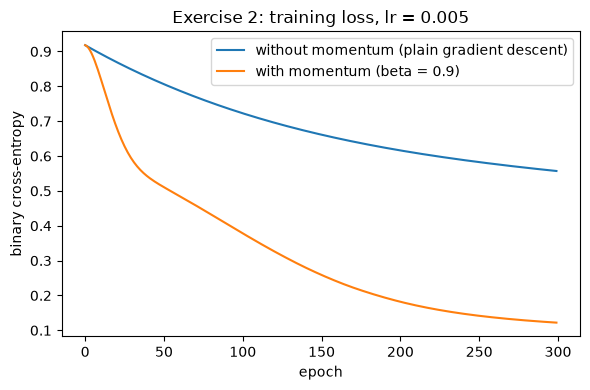

In [17]:
plt.figure(figsize=(6,4))
plt.plot(losses_sgd, label="without momentum (plain gradient descent)")
plt.plot(losses_mom, label="with momentum (beta = 0.9)")
plt.title("Exercise 2: training loss, lr = 0.005")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy")
plt.legend(); plt.tight_layout(); plt.show()

**My interpretation:** Both models start from the same weights and the same loss (0.9180). With momentum the loss falls much faster: after 50 epochs it is 0.5132 with momentum against 0.8080 without, and after 300 epochs it is **0.1221 with momentum against 0.5571 without**. The accuracy after 300 epochs is **0.970 with momentum and 0.806 without**.

Momentum keeps a "velocity" that adds up the past gradients, so when the gradients keep pointing the same way the steps get bigger (up to about 10× with beta = 0.9) and the model moves much faster towards the minimum. When the gradients change direction, the velocity averages them out, which damps the zigzagging. With a small learning rate like 0.005, plain gradient descent is still far from converged after 300 epochs, while momentum is already close.

## Exercise 3: Fine Tuning Activation Functions for an Image Classifier

**As stated in the exercise**  
Task: Experiment with different activation functions to optimize the performance of a convolutional neural network on an image dataset.  
Given data. A dataset of grayscale images of size 28 by 28 pixels with ten categories. A CNN architecture with two convolutional layers, one fully connected layer, and a softmax output layer. The ability to switch activation functions ReLU, Leaky ReLU, and Swish.  

Steps: Train the CNN using ReLU activation and record accuracy. Train the same CNN using Leaky ReLU and compare results. Train the CNN using Swish activation and analyze the effect. Evaluate model performance on test data for all cases. Interpret which activation function works best and why.

**Guidance**  
Use TensorFlow or Keras for this exercise so you focus on the activation comparison rather than low level convolution code. Implement a function that builds the same architecture with a parameter that chooses the activation layer. Ensure identical training settings across runs to isolate the activation effect.

**Learning point**  
Activations trade off sparsity, gradient flow, and smoothness. Leaky ReLU avoids dead neurons. Swish can improve accuracy at modest extra compute due to its smooth gating.



In [18]:
# PREFILLED: just execute
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

print("TensorFlow:", tf.__version__)
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.astype("float32")/255.0
x_test  = x_test.astype("float32")/255.0
x_train = np.expand_dims(x_train, -1)  # (N,28,28,1)
x_test  = np.expand_dims(x_test,  -1)
y_train_oh = to_categorical(y_train, 10)
y_test_oh  = to_categorical(y_test,  10)
x_train.shape, y_train_oh.shape

TensorFlow: 2.21.0


((60000, 28, 28, 1), (60000, 10))

In [19]:
# To-Do: implement build_cnn(activation_name) returning a compiled model
# Allowed activations: 'relu', 'leaky_relu', 'swish'
# Hints: use layers.LeakyReLU(alpha=0.1) and tf.nn.swish or layers.Activation('swish')
# (in Keras 3 the 'alpha' argument of LeakyReLU is called 'negative_slope')
def activation_layer(act):
    if act == 'relu':
        return layers.ReLU()
    elif act == 'leaky_relu':
        return layers.LeakyReLU(negative_slope=0.1)
    elif act == 'swish':
        return layers.Activation('swish')
    else:
        raise ValueError('unknown activation')

def build_cnn(act='relu'):
    inputs = layers.Input(shape=(28,28,1))
    x = layers.Conv2D(32, 3, padding='same')(inputs)
    x = activation_layer(act)(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding='same')(x)
    # repeat activation choice
    x = activation_layer(act)(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128)(x)
    # final activation choice before classifier
    x = activation_layer(act)(x)
    outputs = layers.Dense(10, activation='softmax')(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

In [20]:
# To-Do: train three models with identical epochs and batch size
results = {}
for act in ['relu','leaky_relu','swish']:
    print(f"Training with {act}...")
    tf.keras.utils.set_random_seed(42)   # same starting weights and data order for every activation
    model = build_cnn(act)
    hist = model.fit(x_train, y_train_oh, validation_split=0.1, epochs=2, batch_size=128, verbose=2)
    test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
    results[act] = dict(test_acc=float(test_acc), test_loss=float(test_loss), history=hist.history)

for act, r in results.items():
    print(f"{act:<11} test accuracy = {r['test_acc']:.4f}   test loss = {r['test_loss']:.4f}")

Training with relu...


Epoch 1/2


422/422 - 4s - 9ms/step - accuracy: 0.9404 - loss: 0.2050 - val_accuracy: 0.9840 - val_loss: 0.0601


Epoch 2/2


422/422 - 3s - 7ms/step - accuracy: 0.9832 - loss: 0.0546 - val_accuracy: 0.9878 - val_loss: 0.0469


Training with leaky_relu...


... (6 outputs left out)

422/422 - 5s - 11ms/step - accuracy: 0.9307 - loss: 0.2452 - val_accuracy: 0.9822 - val_loss: 0.0664


Epoch 2/2


422/422 - 4s - 9ms/step - accuracy: 0.9818 - loss: 0.0573 - val_accuracy: 0.9875 - val_loss: 0.0459


relu        test accuracy = 0.9872   test loss = 0.0388
leaky_relu  test accuracy = 0.9878   test loss = 0.0383
swish       test accuracy = 0.9869   test loss = 0.0381


**To-Do:** Create a bar chart of test accuracy for each activation. Summarize in four sentences the trade offs observed.


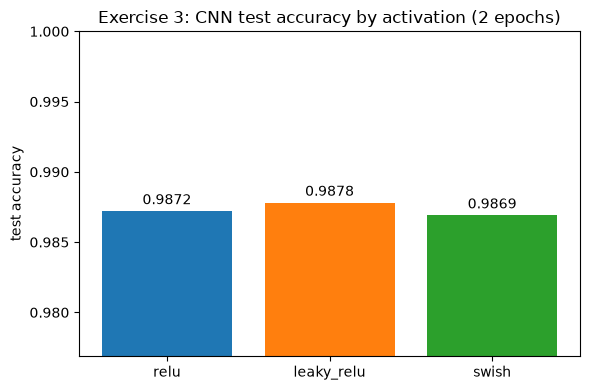

In [21]:
names = list(results.keys())
accs = [results[a]['test_acc'] for a in names]
plt.figure(figsize=(6,4))
bars = plt.bar(names, accs, color=["tab:blue", "tab:orange", "tab:green"])
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2, acc + 0.0005, f"{acc:.4f}", ha="center")
plt.ylim(min(accs) - 0.01, 1.0)
plt.title("Exercise 3: CNN test accuracy by activation (2 epochs)")
plt.ylabel("test accuracy")
plt.tight_layout(); plt.show()

**My interpretation:** | Activation | Test accuracy | Test loss |
|---|---|---|
| ReLU | 0.9872 | 0.0388 |
| Leaky ReLU | **0.9878** | 0.0383 |
| Swish | 0.9869 | 0.0381 |

1. All three activations give almost the same result on MNIST after 2 epochs: **Leaky ReLU is best with 0.9878**, then ReLU 0.9872 and Swish 0.9869. The gap is only 0.09 percentage points (9 images out of 10,000), so with one run and 2 epochs I cannot say that one is really better.
2. Leaky ReLU keeps a small slope (0.1) for negative values, so no neuron can "die" with a zero gradient, which may explain its small edge here.
3. Swish is smooth and had the lowest test loss (0.0381), but it learned a bit slower in the first epoch (0.9307 train accuracy against about 0.94 for the other two) and its training steps were a bit slower, because it needs a sigmoid for every value.
4. ReLU stays a strong and cheap default; for a small CNN on an easy dataset like MNIST, the choice of activation matters much less than the architecture and the number of epochs, and to compare them fairly I would train longer and repeat with several seeds.

## Conclusion

You implemented a deep network from scratch, optimized training with momentum, and compared activation functions in a CNN. For additional challenges, try implementing batch normalization or dropout for regularization, and compare their impact on convergence and accuracy.
